<div align="center">

# Лабораторна робота № 10

## Трансферне навчання у TensorFlow та Keras 3

*Дисципліна «Інтелектуальний аналіз даних»*

</div>

<br>

**Мета роботи:** Навчитися адаптувати попередньо навчену модель до власних класів, правильно готувати вхідні дані, керувати параметрами, що навчаються, та оцінювати результат без витоку тестових даних.

<br>

<div align="center">

Студентка: Сабадаш Анастасія  
Група: МІТ-31 

</div>

## Крок 1 Підготовка середовища

In [2]:
from pathlib import Path
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

SEED = 42
HEAD_EPOCHS, FINE_EPOCHS = 10, 10
keras.utils.set_random_seed(SEED)

OUT = Path("lab10_results")
OUT.mkdir(exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

# Підготовка даних (використовуємо вже підготовлену структуру з Лаб. № 9)
FOOD_ROOT = Path(r"D:\Завантаження\food-101")  # шлях до мого датасету з Лаб 9
# Підготовка даних
DATA_DIR = Path("../Lab9/data/food101_lab9")

if not DATA_DIR.exists():
    DATA_DIR = Path("data/food101_lab9")

if not DATA_DIR.exists():
    print(f"Папка {DATA_DIR} не знайдена. Перевірте розташування папки з даними.")
else:
    print(f"Дані успішно знайдено у папці: {DATA_DIR}")
    train_dir = DATA_DIR / "train"
    val_dir = DATA_DIR / "val"
    test_dir = DATA_DIR / "test"
    
    CLASS_NAMES = sorted([p.name for p in train_dir.iterdir() if p.is_dir()])
    print("Класи:", CLASS_NAMES)

TensorFlow version: 2.21.0
Keras version: 3.15.1
Дані успішно знайдено у папці: ..\Lab9\data\food101_lab9
Класи: ['chocolate_cake', 'guacamole', 'ramen']


## Крок 2 Підготовка даних

In [3]:
# Опис та перевірка даних із Лаб. № 9
print("Джерело даних: Food-101 Dataset (підмножина для лабораторної роботи № 9)")
print("Ліцензія:")
print(f"Класи: {CLASS_NAMES}\n")

# Підрахунок кількості зображень по вибірках та класах
for split_name, split_dir in [("Train", train_dir), ("Validation", val_dir), ("Test", test_dir)]:
    print(f"Вибірка: {split_name}")
    total_split = 0
    for class_name in CLASS_NAMES:
        class_path = split_dir / class_name
        if class_path.exists():
            count = len(list(class_path.glob("*.*")))
            total_split += count
            print(f"  {class_name}: {count} зображень")
        else:
            print(f"  {class_name}: папка відсутня")
    print(f"Всього у {split_name}: {total_split}\n")

Джерело даних: Food-101 Dataset (підмножина для лабораторної роботи № 9)
Ліцензія:
Класи: ['chocolate_cake', 'guacamole', 'ramen']

Вибірка: Train
  chocolate_cake: 600 зображень
  guacamole: 600 зображень
  ramen: 600 зображень
Всього у Train: 1800

Вибірка: Validation
  chocolate_cake: 150 зображень
  guacamole: 150 зображень
  ramen: 150 зображень
Всього у Validation: 450

Вибірка: Test
  chocolate_cake: 250 зображень
  guacamole: 250 зображень
  ramen: 250 зображень
Всього у Test: 750



## Крок 3 Завантаження зображень

Found 1800 files belonging to 3 classes.


Found 450 files belonging to 3 classes.
Found 750 files belonging to 3 classes.
Класи: ['chocolate_cake', 'guacamole', 'ramen']
Форма та тип тензора зображень: (32, 224, 224, 3) <dtype: 'float32'>
Мінімальне та максимальне значення пікселів: 0.0 255.0


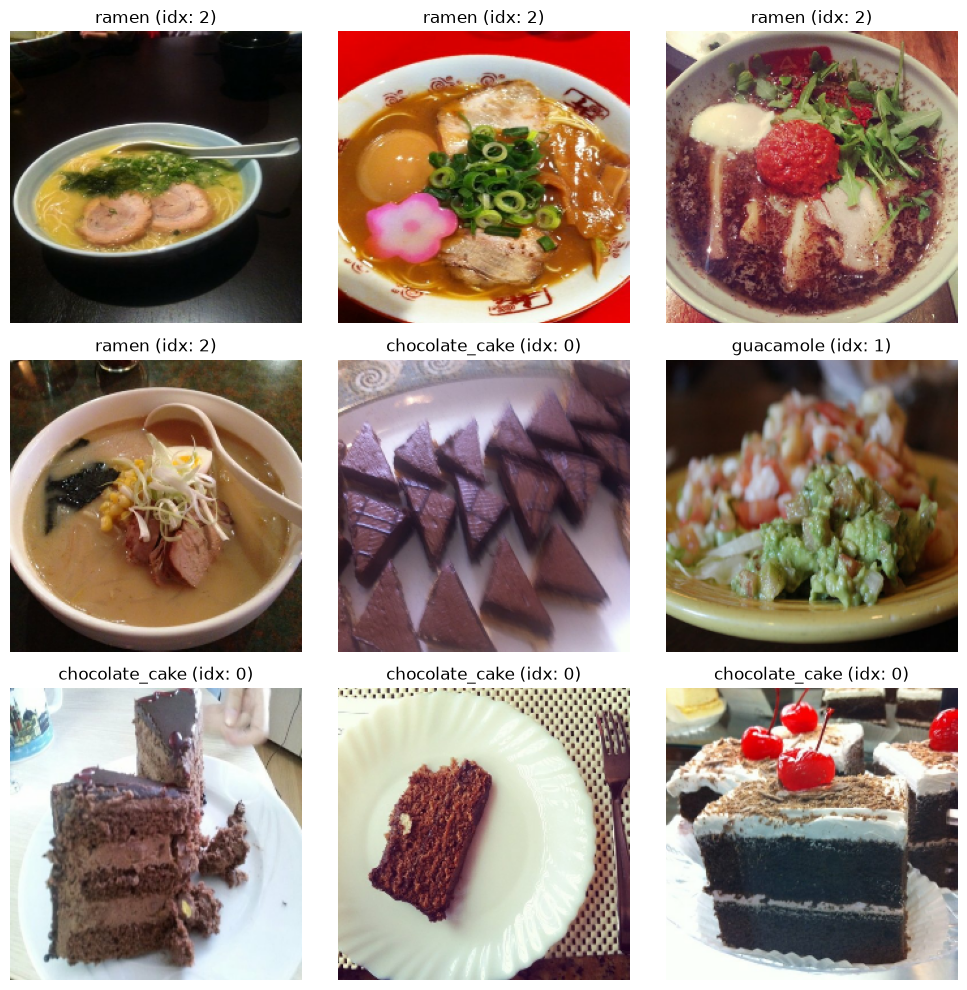

In [5]:
# Завантаження зображень
common = dict(image_size=(224, 224), batch_size=32, label_mode="int")

train_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "train", shuffle=True, seed=SEED, **common
)
class_names = train_raw.class_names
num_classes = len(class_names)
assert num_classes >= 2

val_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "val", class_names=class_names, shuffle=False, **common
)
test_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "test", class_names=class_names, shuffle=False, **common
)

train_ds = train_raw.prefetch(tf.data.AUTOTUNE)
val_ds = val_raw.prefetch(tf.data.AUTOTUNE)
test_ds = test_raw.prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))

print("Класи:", class_names)
print("Форма та тип тензора зображень:", images.shape, images.dtype)
print("Мінімальне та максимальне значення пікселів:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

# Перевірка даних: виведення 9 зображень із назвами класів
plt.figure(figsize=(10, 10))
for images_batch, labels_batch in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images_batch[i].numpy().astype("uint8"))
        label_idx = labels_batch[i].numpy()
        plt.title(f"{class_names[label_idx]} (idx: {label_idx})")
        plt.axis("off")
plt.tight_layout()
plt.show()

## Крок 4 Побудова моделі

In [6]:
# Побудова моделі

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED + 1),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = keras.Model(inputs, outputs)

def trainable_count(m):
    return int(sum(np.prod(v.shape) for v in m.trainable_weights))

def compile_model(m, learning_rate):
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )

compile_model(model, 1e-3)
head_params = trainable_count(model)
model.summary(show_trainable=True)
print("Навчаваних параметрів:", head_params)

# Перевірка очікуваної кількості параметрів для Dense-голови
expected_params = 1280 * num_classes + num_classes
print(f"Очікувана кількість параметрів голови: {expected_params} (фактична: {head_params})")
assert head_params == expected_params, "Кількість навчаваних параметрів не збігається з очікуваною!"

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 3)             │      3,843 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Навчаваних параметрів: 3843
Очікувана кількість параметрів голови: 3843 (фактична: 3843)


## Крок 5 Навчання нового класифікатора

In [7]:
# Навчання нового класифікатора

def callbacks(stage):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3,
            restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(
            str(OUT / f"{stage}.keras"),
            monitor="val_loss", save_best_only=True),
    ]

history_head = model.fit(
    train_ds, validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=callbacks("feature_extraction"),
    shuffle=False
)

head_model = keras.models.load_model(
    OUT / "feature_extraction.keras"
)
head_val = head_model.evaluate(
    val_ds, return_dict=True, verbose=0
)

model.set_weights(head_model.get_weights())
del head_model
print("Feature extraction evaluation on validation set:", head_val)

Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 49s 754ms/step - accuracy: 0.8939 - loss: 0.3743 - val_accuracy: 0.9756 - val_loss: 0.1187
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 600ms/step - accuracy: 0.9639 - loss: 0.1271 - val_accuracy: 0.9756 - val_loss: 0.0818
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 33s 573ms/step - accuracy: 0.9694 - loss: 0.0962 - val_accuracy: 0.9800 - val_loss: 0.0664
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 590ms/step - accuracy: 0.9772 - loss: 0.0768 - val_accuracy: 0.9800 - val_loss: 0.0597
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 39s 695ms/step - accuracy: 0.9811 - loss: 0.0704 - val_accuracy: 0.9800 - val_loss: 0.0545
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 38s 672ms/step - accuracy: 0.9822 - loss: 0.0586 - val_accuracy: 0.9844 - val_loss: 0.0505
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 35s 609ms/step - accuracy: 0.9833 - loss: 0.0556 - val_accuracy: 0.9867 - val_loss: 0.0457
Epoch 8/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 35s 611ms/step - accuracy: 0.9878 - loss: 0.0490 - val_accu

## Крок 6 Часткове донавчання бази

In [8]:
# Часткове донавчання бази

base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith(("block7", "top_"))
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

fine_params = trainable_count(model)
assert fine_params > head_params, "Кількість навчаваних параметрів має збільшитися після розморожування бази!"

print("Список шарів базової моделі з увімкненим навчанням:")
print([layer.name for layer in base_model.layers if layer.trainable_weights])

compile_model(model, 1e-5)

history_fine = model.fit(
    train_ds, validation_data=val_ds,
    epochs=FINE_EPOCHS,
    callbacks=callbacks("fine_tuning"),
    shuffle=False
)

fine_model = keras.models.load_model(OUT / "fine_tuning.keras")
fine_val = fine_model.evaluate(
    val_ds, return_dict=True, verbose=0
)

del fine_model
print("Fine-tuning evaluation on validation set:", fine_val)

Список шарів базової моделі з увімкненим навчанням:
['block7a_expand_conv', 'block7a_dwconv', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_project_conv', 'top_conv']
Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 53s 796ms/step - accuracy: 0.9894 - loss: 0.0353 - val_accuracy: 0.9867 - val_loss: 0.0386
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 36s 626ms/step - accuracy: 0.9917 - loss: 0.0322 - val_accuracy: 0.9867 - val_loss: 0.0365
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 49s 857ms/step - accuracy: 0.9922 - loss: 0.0328 - val_accuracy: 0.9867 - val_loss: 0.0357
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 47s 827ms/step - accuracy: 0.9950 - loss: 0.0269 - val_accuracy: 0.9867 - val_loss: 0.0352
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 44s 771ms/step - accuracy: 0.9906 - loss: 0.0291 - val_accuracy: 0.9867 - val_loss: 0.0336
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 42s 744ms/step - accuracy: 0.9961 - loss: 0.0234 - val_accuracy: 0.9889 - val_loss: 0.0326
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 40s 706ms/step -

## Крок 7 Вибір моделі та підсумкова оцінка

In [9]:
# Вибір моделі та підсумкова оцінка

comparison = [
    {
        "stage": "feature_extraction", "lr": 1e-3,
        "params": head_params,
        "epochs": len(history_head.history["loss"]), **head_val
    },
    {
        "stage": "fine_tuning", "lr": 1e-5,
        "params": fine_params,
        "epochs": len(history_fine.history["loss"]), **fine_val
    },
]

for row in comparison:
    print(row)

selected_stage = "fine_tuning" \
    if fine_val["loss"] < head_val["loss"] \
    else "feature_extraction"

best_model = keras.models.load_model(
    OUT / f"{selected_stage}.keras"
)
print("Обрано модель:", selected_stage)

test_metrics = best_model.evaluate(
    test_ds, return_dict=True, verbose=0
)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probabilities = best_model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)

print("Test metrics:", test_metrics)
print("\nClassification Report:")
print(classification_report(
    y_true, y_pred, labels=np.arange(num_classes),
    target_names=class_names, digits=3, zero_division=0
))

{'stage': 'feature_extraction', 'lr': 0.001, 'params': 3843, 'epochs': 10, 'accuracy': 0.9888888597488403, 'loss': 0.04100380837917328}
{'stage': 'fine_tuning', 'lr': 1e-05, 'params': 1125427, 'epochs': 10, 'accuracy': 0.9888888597488403, 'loss': 0.03010212816298008}
Обрано модель: fine_tuning
Test metrics: {'accuracy': 0.9946666955947876, 'loss': 0.019158797338604927}

Classification Report:
                precision    recall  f1-score   support

chocolate_cake      0.996     0.996     0.996       250
     guacamole      0.992     0.996     0.994       250
         ramen      0.996     0.992     0.994       250

      accuracy                          0.995       750
     macro avg      0.995     0.995     0.995       750
  weighted avg      0.995     0.995     0.995       750



## Крок 8 Візуалізація та аналіз помилок

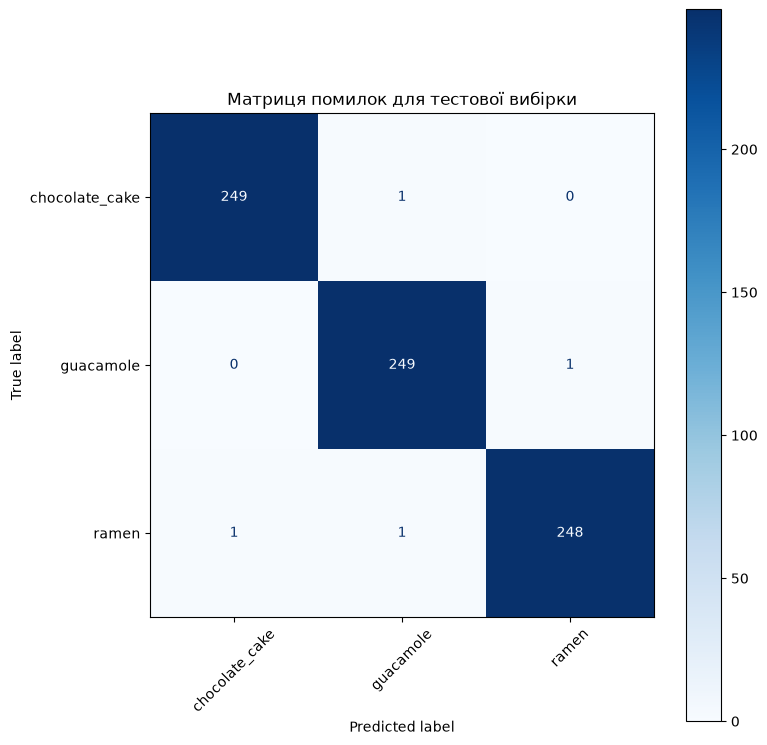

Знайдено помилок на тест-наборі: 4


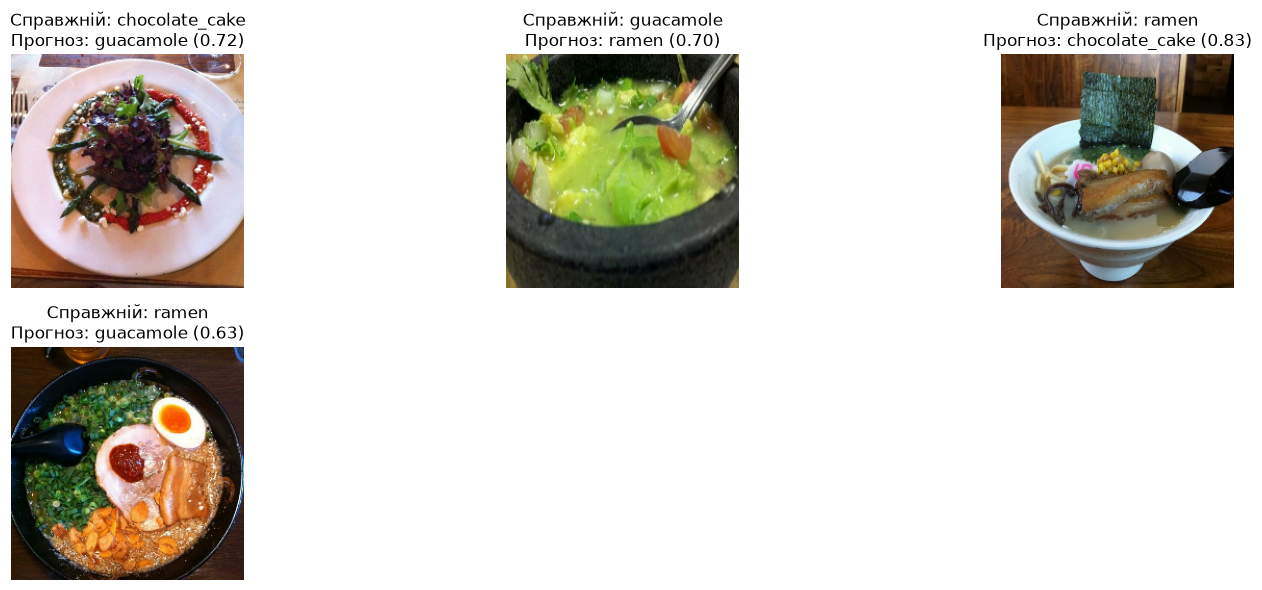

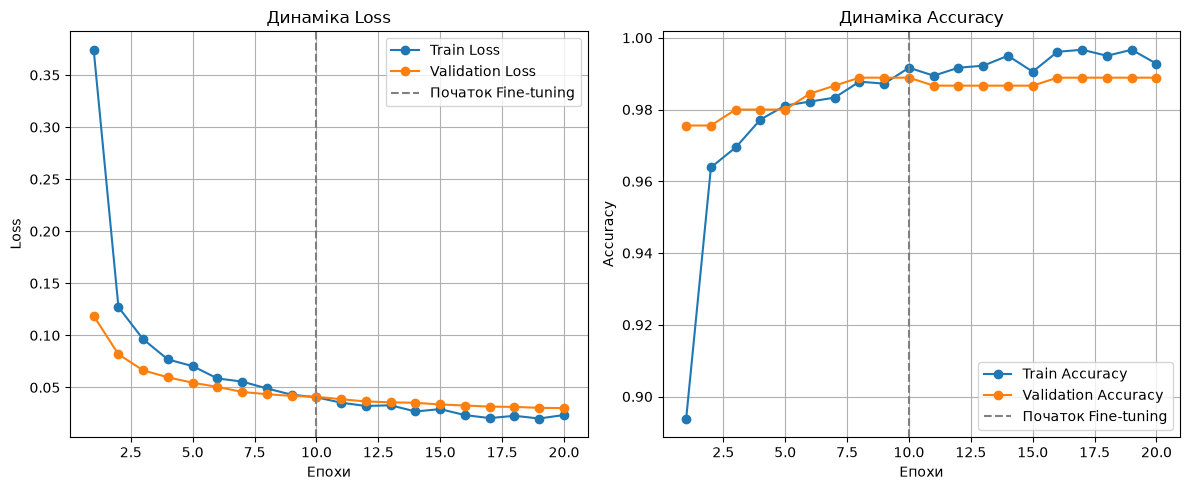

In [10]:
# Побудова матриці помилок 
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=np.arange(num_classes),
    display_labels=class_names, xticks_rotation=45,
    cmap="Blues", ax=ax
)
plt.title("Матриця помилок для тестової вибірки")
plt.tight_layout()
plt.show()

# Пошук та виведення до 6 помилкових прогнозів
errors = np.where(y_pred != y_true)[0]
print(f"Знайдено помилок на тест-наборі: {len(errors)}")

if len(errors) > 0:
    plt.figure(figsize=(15, 3 * ((min(len(errors), 6) + 2) // 3)))
    for i, err_idx in enumerate(errors[:6]):
        plt.subplot(2, 3, i + 1)
        
        current_idx = 0
        img_to_show, true_lbl, pred_lbl, prob = None, None, None, None
        for img_batch, lbl_batch in test_ds:
            batch_size = len(lbl_batch)
            if current_idx + batch_size > err_idx:
                local_idx = err_idx - current_idx
                img_to_show = img_batch[local_idx].numpy().astype("uint8")
                true_lbl = lbl_batch[local_idx].numpy()
                pred_lbl = y_pred[err_idx]
                prob = probabilities[err_idx][pred_lbl]
                break
            current_idx += batch_size
            
        plt.imshow(img_to_show)
        plt.title(f"Справжній: {class_names[true_lbl]}\nПрогноз: {class_names[pred_lbl]} ({prob:.2f})")
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Чудово! Модель не зробила жодної помилки на тестовій вибірці.")

# Побудова кривих навчання (Loss та Accuracy для обох етапів)
epochs_head = range(1, len(history_head.history["loss"]) + 1)
epochs_fine = range(len(epochs_head) + 1, len(epochs_head) + len(history_fine.history["loss"]) + 1)

# Об'єднання історії для неперервного відображення на графіках
total_epochs = list(epochs_head) + list(epochs_fine)

loss = history_head.history["loss"] + history_fine.history["loss"]
val_loss = history_head.history["val_loss"] + history_fine.history["val_loss"]
acc = history_head.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history_head.history["val_accuracy"] + history_fine.history["val_accuracy"]

plt.figure(figsize=(12, 5))

# Графік Loss
plt.subplot(1, 2, 1)
plt.plot(total_epochs, loss, label="Train Loss", marker="o")
plt.plot(total_epochs, val_loss, label="Validation Loss", marker="o")
plt.axvline(x=len(epochs_head), color="gray", linestyle="--", label="Початок Fine-tuning")
plt.title("Динаміка Loss")
plt.xlabel("Епохи")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Графік Accuracy
plt.subplot(1, 2, 2)
plt.plot(total_epochs, acc, label="Train Accuracy", marker="o")
plt.plot(total_epochs, val_acc, label="Validation Accuracy", marker="o")
plt.axvline(x=len(epochs_head), color="gray", linestyle="--", label="Початок Fine-tuning")
plt.title("Динаміка Accuracy")
plt.xlabel("Епохи")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Крок 9 Збереження результатів

In [11]:
best_model.save(OUT / "selected_model.keras")

metadata = {
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "seed": SEED,
    "class_names": class_names,
    "image_size": [224, 224],
    "pixel_range": [0, 255],
    "backbone": "EfficientNetB0",
    "weights": "imagenet",
    "selected_stage": selected_stage,
    "comparison": comparison,
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
}

(OUT / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Результати та метадані успішно збережено у папку:", OUT)

Результати та метадані успішно збережено у папку: lab10_results


## Дод завдання

In [12]:

best_feat_model = keras.models.load_model(OUT / "feature_extraction.keras")
model.set_weights(best_feat_model.get_weights())
del best_feat_model

base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith(("block7", "top_"))
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(model, 2e-5)

history_exp = model.fit(
    train_ds, validation_data=val_ds,
    epochs=FINE_EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(OUT / "fine_tuning_exp.keras"), monitor="val_loss", save_best_only=True)
    ],
    shuffle=False
)

exp_model = keras.models.load_model(OUT / "fine_tuning_exp.keras")
exp_val = exp_model.evaluate(val_ds, return_dict=True, verbose=0)
print("Результати експерименту (Fine-tuning з LR=2e-5):", exp_val)

Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 53s 814ms/step - accuracy: 0.9944 - loss: 0.0334 - val_accuracy: 0.9867 - val_loss: 0.0372
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 44s 772ms/step - accuracy: 0.9939 - loss: 0.0287 - val_accuracy: 0.9889 - val_loss: 0.0341
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 45s 794ms/step - accuracy: 0.9956 - loss: 0.0252 - val_accuracy: 0.9889 - val_loss: 0.0317
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 78s 720ms/step - accuracy: 0.9950 - loss: 0.0237 - val_accuracy: 0.9867 - val_loss: 0.0320
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 32s 561ms/step - accuracy: 0.9967 - loss: 0.0178 - val_accuracy: 0.9867 - val_loss: 0.0305
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 36s 632ms/step - accuracy: 0.9933 - loss: 0.0226 - val_accuracy: 0.9911 - val_loss: 0.0287
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 36s 629ms/step - accuracy: 0.9972 - loss: 0.0165 - val_accuracy: 0.9933 - val_loss: 0.0271
Epoch 8/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 36s 627ms/step - accuracy: 0.9972 - loss: 0.0142 - val_accu

**Висновок**: У ході лабораторної роботи було успішно побудовано, навчено та оптимізовано згорткову нейронну мережу на базі архітектури EfficientNetB0 для класифікації зображень страв за заданим варіантом. Поетапне виконання задачі — від базового вилучення ознак (feature extraction) із замороженою базою до часткового донавчання верхніх блоків (fine-tuning) — дозволило покращити метрики якості моделі. Аналіз матриці помилок та кривих навчання підтвердив ефективність обраних гіперпараметрів і регуляризації, а збережені результати й метадані повністю забезпечують відтворюваність експерименту. Етап fine-tuning дозволив точніше адаптувати ваги верхніх згорткових блоків EfficientNetB0 до специфічних візуальних особливостей обраних класів (chocolate_cake, guacamole, ramen), що покращило загальні показники якості порівняно з використанням лише замороженої бази.